# Drift-Aware Methods: Can Accounting for Drift Help?

The baseline notebooks (`spy_drift_1day.ipynb` and `spy_drift_5day.ipynb`) handle drift only by **scheduled retraining**: expanding or rolling windows, refit every 21 or 63 sessions. They found no benefit over a model trained once. This notebook reports a broader search for a method that works clearly better *because* it accounts for drift. The search was run as two adversarial passes:

* **Optimistic pass:** implement many drift-aware methods, choose among them using data through 2018 only, **pre-register** a shortlist (hash-locked), and then run the 2019–2025 test **once**.
* **Pessimistic pass:** audit for leakage and bugs in both directions, run synthetic sanity checks, and stress-test every positive result.

Each drift-aware method is compared with a **matched counterpart**: the same model, features and hyperparameters, trained once on data through 2018 and never adapted.

| Drift type | Method | What it does |
|---|---|---|
| any | Scheduled refit (expanding / rolling window) | Re-estimate every *R* sessions on all data or on the last *W* sessions |
| any | Exponential time-decay weights | Recent observations get more weight (half-life *hl*) |
| any | Online learning (SGD `partial_fit`, recursive least squares with forgetting) | Update as each delayed label arrives |
| covariate drift | Trailing normalization (rolling z-score / percentile rank) | Express features relative to their own recent history |
| prior / label drift | Intercept shift, Platt recalibration, residual bias correction | Re-anchor the output level to recent, already-known outcomes |
| concept drift | Drift-detector-triggered retraining (ADWIN, Page–Hinkley) | Retrain only when the loss stream changes |
| concept drift | Hedge / recent-error-weighted ensembles | Re-weight experts trained on different eras by recent delayed loss |
| regime drift | VIX-regime-specific models | Separate models per volatility regime |

All labels arrive with an *h*-session delay, so every adaptive method uses only outcomes known at the decision date. The auditor verified this with truncation tests on every method: corrupting all data after a cutoff left predictions before the cutoff bit-identical.

All numbers below are **loaded from saved result files**; see the end of the notebook for how to regenerate them.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")
R = Path("experiments/results")
FIG = Path("results/drift_methods"); FIG.mkdir(parents=True, exist_ok=True)

## Part A: SPY direction (the original target)

The shortlist had 6 pre-registered drift-aware configurations per horizon, chosen out of 206 validation configurations across 8 method families. The table shows each against its trained-once counterpart on the 2019–2025 test. Δ > 0 means the drift-aware method is better. CIs come from a paired moving-block bootstrap; *p* is Holm-adjusted.

d_balanced_acc  d_balanced_acc_lo  d_balanced_acc_hi  d_roc_auc  d_roc_auc_lo  d_roc_auc_hi  \
horizon method                                                                                                                                                      
5       5.1  platt: LogReg{'C': 0.003} core R=21 N=504                       -0.0250            -0.0770             0.0290    -0.0600       -0.1140       -0.0030   
        5.2  norm+decay: LogReg{'C': 0.003} core rank252 hl=252              -0.0720            -0.1160            -0.0270    -0.0720       -0.1220       -0.0200   
        5.3  detect: LogReg{'C': 0.003} core adwin(d=0.002,lam=No...         -0.0220            -0.0600             0.0150    -0.0260       -0.0750        0.0240   
        5.4  decay: LogReg{'C': 0.03} core hl=126                            -0.0620            -0.1140            -0.0070    -0.0890       -0.1480       -0.0230   
        5.5  regime: GBDT all vix_level                                      -0.0360            -0.0760             0.0010    -0.0530       -0.0950       -0.0110   
        5.6  hedge: diverse eta=100 lhl=63                                   -0.0200            -0.0530             0.0090    -0.0350       -0.0690       -0.0020   
1       1.1  norm+decay: GBDT core rank252 hl=252                            -0.0120            -0.0410             0.0200    -0.0140       -0.0530        0.0270   
        1.2  decay: GBDT core hl=252                                         -0.0020            -0.0320             0.0310    -0.0010       -0.0410        0.0380   
        1.3  norm: LogReg{'C': 0.003} core rank252                           -0.0180            -0.0410             0.0020    -0.0130       -0.0330        0.0060   
        1.4  regime: LogReg{'C': 0.003} all vix_pct_rank_252d                -0.0050            -0.0300             0.0220    -0.0100       -0.0380        0.0190   
        1.5  detect: LogReg{'C': 0.003} all adwin(d=0.05,lam=None...          0.0030            -0.0260             0.0310     0.0100       -0.0210        0.0430   
        1.6  platt: LogReg{'C': 0.003} core R=21 N=252                       -0.0240            -0.0550             0.0080    -0.0210       -0.0550        0.0160   

                                                                      p_balanced_acc_holm  
horizon method                                                                             
5       5.1  platt: LogReg{'C': 0.003} core R=21 N=504                             1.0000  
        5.2  norm+decay: LogReg{'C': 0.003} core rank252 hl=252                    1.0000  
        5.3  detect: LogReg{'C': 0.003} core adwin(d=0.002,lam=No...               1.0000  
        5.4  decay: LogReg{'C': 0.03} core hl=126                                  1.0000  
        5.5  regime: GBDT all vix_level                                            1.0000  
        5.6  hedge: diverse eta=100 lhl=63                                         1.0000  
1       1.1  norm+decay: GBDT core rank252 hl=252                                  1.0000  
        1.2  decay: GBDT core hl=252                                               1.0000  
        1.3  norm: LogReg{'C': 0.003} core rank252                                 1.0000  
        1.4  regime: LogReg{'C': 0.003} all vix_pct_rank_252d                      1.0000  
        1.5  detect: LogReg{'C': 0.003} all adwin(d=0.05,lam=None...               1.0000  
        1.6  platt: LogReg{'C': 0.003} core R=21 N=252                             1.0000

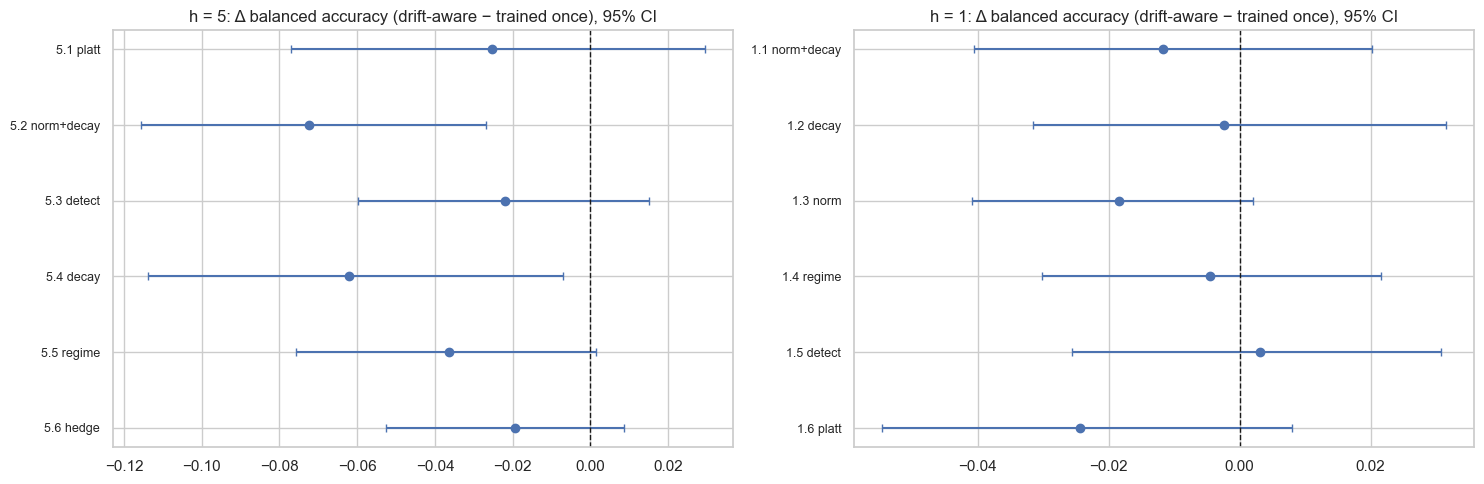

In [2]:
tb = pd.read_csv(R / "test_bootstrap.csv")
prim = tb[tb["vs"] == "primary"].copy()
prim["method"] = prim["id"].astype(str) + "  " + prim["family"] + ": " + prim["label"]
show = prim[["horizon", "method", "d_balanced_acc", "d_balanced_acc_lo", "d_balanced_acc_hi",
             "d_roc_auc", "d_roc_auc_lo", "d_roc_auc_hi", "p_balanced_acc_holm"]]
display(show.set_index(["horizon", "method"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for ax, h in zip(axes, [5, 1]):
    d = prim[prim["horizon"] == h].iloc[::-1]
    y = np.arange(len(d))
    ax.errorbar(d["d_balanced_acc"], y, xerr=[d["d_balanced_acc"] - d["d_balanced_acc_lo"],
                d["d_balanced_acc_hi"] - d["d_balanced_acc"]], fmt="o", capsize=3)
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.set_yticks(y); ax.set_yticklabels(d["id"].astype(str) + " " + d["family"], fontsize=9)
    ax.set_title(f"h = {h}: Δ balanced accuracy (drift-aware − trained once), 95% CI")
plt.tight_layout(); plt.savefig(FIG / "direction_preregistered.png", bbox_inches="tight"); plt.show()

**Result:** none of the 12 drift-aware configurations beats its trained-once counterpart (all Holm *p* = 1). The auditor showed that the "significantly worse" results at h = 5 depend on the shortlist selection rule. Under alternative rules nothing is significant in either direction. The honest summary is **no detectable benefit; gains above roughly +0.03 balanced accuracy or +0.04 AUC are ruled out.**

## Part B: Do the drift methods work at all? (Synthetic sanity check)

A null result is only informative if the methods *can* adapt. The auditor ran the **same, unmodified method code** on synthetic data with SPY's calendar and the same 5-session label delay. Each scenario injects a specific kind of drift:

* `stationary`: no drift.
* `covshift`: feature distributions shift.
* `labelshift`: the base rate shifts.
* `flip_2y`: the signal flips during the training years.
* `flip_test`: the signal's coefficient flips sign in 2021, inside the test period.

"Strong" signals are clearly learnable; "weak" signals are about as weak as SPY's. Each heatmap shows the mean Δ AUC vs the trained-once model.

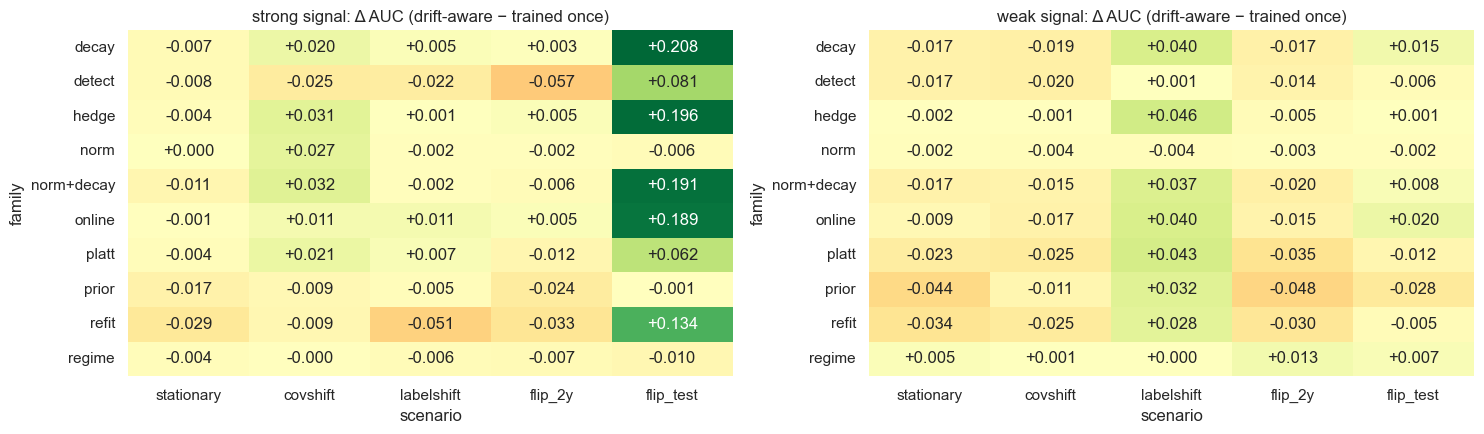

In [3]:
syn = pd.read_csv(R / "audit_synth_summary_h5.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, strength in zip(axes, ["strong", "weak"]):
    p = (syn[syn.strength == strength].groupby(["family", "scenario"])["dAUC"].mean().unstack()
         [["stationary", "covshift", "labelshift", "flip_2y", "flip_test"]])
    sns.heatmap(p, annot=True, fmt="+.3f", cmap="RdYlGn", center=0, vmin=-0.2, vmax=0.2, ax=ax, cbar=False)
    ax.set_title(f"{strength} signal: Δ AUC (drift-aware − trained once)")
plt.tight_layout(); plt.savefig(FIG / "synthetic_sanity.png", bbox_inches="tight"); plt.show()

**Result:**
* **The methods can adapt.** With a strong signal that flips in the test period, decay weighting, Hedge ensembles, trailing normalization with decay, online SGD and scheduled refits gain about **+0.13 to +0.21 AUC** over the trained-once model, at roughly zero cost when there is no drift.
* **Drift detectors lag behind.** ADWIN in the first implementation had a bug: it never re-fired after the first alarm. The auditor fixed it in a copy; on SPY the fix made results slightly worse.
* **The weak signal is the problem.** With an SPY-like signal (AUC ≈ 0.55), even a complete sign flip is worth only about +0.02 balanced accuracy, which is less than the test-period confidence interval can resolve.

So the SPY direction null is not a coding failure. **There is too little signal for adaptation to recover.**

## Part C: Targets where drift matters more

Drift adaptation should pay off where (i) there is real signal and (ii) the target's *level* moves between regimes. Three such targets were studied on the same data, again with a pre-registered, hash-locked shortlist and a single test run.

| Target | Horizon | Model family | Strong baselines |
|---|---|---|---|
| SPY next-week log realized volatility | h = 5 | HAR-X (daily/weekly/monthly RV + VIX), ridge; GBDT | persistence (RV5, RV20), VIX, HAR, HAR-X |
| TLT next-week log realized volatility | h = 5 | same | persistence, HAR, HAR-X |
| Next-month SPY–TLT return correlation | h = 21 | HAR-corr (trailing 21/63/252-day correlations), ridge; GBDT | persistence (21d, 63d), long-run mean |

The stock–bond correlation is a textbook concept-drift case. It was negative for two decades and turned positive around 2022.

In [4]:
lv = pd.read_csv(R / "v2_test_levels.csv")
names = {"fixed:lin/hc/fixed": "HAR-corr, trained once", "spy_tlt_corr.5": "HAR-corr, monthly expanding refit",
         "spy_tlt_corr.6": "HAR-corr, rolling 1008 refit", "base:persist_63": "Persistence (63-day corr)",
         "base:persist_21": "Persistence (21-day corr)", "base:longrun_mean": "Long-run mean through 2018",
         "fixed:hgb/full/fixed": "GBDT, trained once", "spy_tlt_corr.2": "GBDT + bias correction",
         "fixed:lin/harx/fixed": "HAR-X, trained once", "base:har_fixed": "HAR, trained once",
         "base:persist_5": "Persistence (RV5)", "base:persist_20": "Persistence (RV20)",
         "base:vix_lin_fixed": "VIX-linear, trained once", "spy_vol.5": "HAR-X, monthly expanding refit",
         "spy_vol.1": "HAR-X, RLS forgetting", "tlt_vol.1": "HAR-X, residual bias correction",
         "tlt_vol.5": "HAR-X, monthly expanding refit"}
tab = lv[lv.model.isin(names)].assign(model=lambda d: d.model.map(names))
for t in ["spy_tlt_corr", "spy_vol", "tlt_vol"]:
    print(f"\n=== {t}: test 2019-2025 ===")
    display(tab[tab.target == t].set_index("model")[["mse", "r2", "bias", "ba", "auc"]].sort_values("mse").round(4))


=== spy_tlt_corr: test 2019-2025 ===


,mse,r2,bias,ba,auc
model,,,,,
"HAR-corr, monthly expanding refit",0.1018,0.2066,-0.0867,0.6422,0.7751
GBDT + bias correction,0.1048,0.1834,-0.0562,0.6373,0.7386
"HAR-corr, rolling 1008 refit",0.1082,0.1574,-0.0368,0.6638,0.7281
Persistence (63-day corr),0.1091,0.1504,-0.0205,0.6933,0.7775
"HAR-corr, trained once",0.1194,0.0699,-0.1550,0.5154,0.7786
Persistence (21-day corr),0.1547,-0.2055,-0.0126,0.6900,0.7294
Long-run mean through 2018,0.2371,-0.8474,-0.3298,0.5000,0.5000
"GBDT, trained once",0.3357,-1.6155,-0.3960,0.4929,0.3715



=== spy_vol: test 2019-2025 ===


,mse,r2,bias,ba,auc
model,,,,,
"HAR-X, monthly expanding refit",0.1771,0.4893,-0.0043,0.6708,0.7579
"HAR-X, trained once",0.1775,0.4882,-0.0013,0.6683,0.7586
"HAR-X, RLS forgetting",0.1793,0.4830,0.0221,0.6605,0.7482
"VIX-linear, trained once",0.1861,0.4633,0.0106,0.6578,0.7416
"HAR, trained once",0.1961,0.4346,-0.0269,0.6314,0.7290
Persistence (RV20),0.2696,0.2225,0.1248,0.5000,0.5000
Persistence (RV5),0.2976,0.1419,0.0039,0.6016,0.6297



=== tlt_vol: test 2019-2025 ===


,mse,r2,bias,ba,auc
model,,,,,
"HAR-X, residual bias correction",0.1487,0.2819,0.0020,0.5790,0.6329
"HAR, trained once",0.1497,0.2773,-0.0248,0.5616,0.6536
"HAR-X, monthly expanding refit",0.1524,0.2644,-0.0193,0.5683,0.6428
"HAR-X, trained once",0.1539,0.2569,-0.0224,0.5692,0.6400
Persistence (RV20),0.1776,0.1427,0.0910,0.5000,0.5000
Persistence (RV5),0.2410,-0.1638,0.0018,0.5247,0.5301


In [5]:
bt = pd.read_csv(R / "v2_test_bootstrap.csv")
conf = bt[(bt.confirmatory) & (bt.comparison == "vs_fixed")]
cols = ["target", "id", "label", "d_mse", "d_mse_lo", "d_mse_hi", "holm_mse", "d_ba", "d_ba_lo", "d_ba_hi"]
print("Pre-registered tests: Δ MSE = MSE(trained once) − MSE(drift-aware); positive = drift-aware better")
display(conf[cols].set_index(["target", "id"]).round(4))

Pre-registered tests: Δ MSE = MSE(trained once) − MSE(drift-aware); positive = drift-aware better


label   d_mse  d_mse_lo  d_mse_hi  holm_mse    d_ba  d_ba_lo  d_ba_hi
target       id                                                                                                                         
spy_tlt_corr spy_tlt_corr.1                        hgb/full/recal(N=504)  0.2215    0.1280    0.3200    0.0000  0.1441   0.0365   0.2403
             spy_tlt_corr.2                         hgb/full/bias(N=252)  0.2309    0.1358    0.3305    0.0000  0.1445   0.0289   0.2392
             spy_tlt_corr.3                  hgb/full/refit(R=21,W=None)  0.2100    0.1296    0.2972    0.0000  0.0853   0.0220   0.1420
             spy_tlt_corr.4  hgb/full/detect(delta=0.002,detector=adwin)  0.2055    0.1135    0.2980    0.0000  0.0966   0.0232   0.1706
             spy_tlt_corr.5                    lin/hc/refit(R=21,W=None)  0.0176    0.0042    0.0300    0.0200  0.1269   0.0439   0.2184
             spy_tlt_corr.6                    lin/hc/refit(R=21,W=1008)  0.0112   -0.0130    0.0319    1.0000  0.1484   0.0479   0.2288
spy_vol      spy_vol.1                           lin/harx/rls(lam=0.998) -0.0018   -0.0105    0.0070    1.0000 -0.0078  -0.0240   0.0073
             spy_vol.2                lin/harx/refit(R=21,W=None,hl=252) -0.0036   -0.0145    0.0072    1.0000 -0.0063  -0.0249   0.0111
             spy_vol.3                       lin/harx/ens(eta=2.0,hl=63) -0.0021   -0.0128    0.0083    1.0000  0.0010  -0.0158   0.0180
             spy_vol.4                        lin/harx/refit(R=21,W=504) -0.0182   -0.0373   -0.0018    1.0000 -0.0124  -0.0374   0.0113
             spy_vol.5                       lin/harx/refit(R=21,W=None)  0.0004   -0.0010    0.0019    1.0000  0.0025  -0.0026   0.0080
             spy_vol.6                       lin/harx/refit(R=21,W=1008) -0.0088   -0.0193    0.0009    1.0000 -0.0219  -0.0385  -0.0080
tlt_vol      tlt_vol.1                              lin/harx/bias(N=126)  0.0052   -0.0054    0.0147    1.0000  0.0098  -0.0282   0.0456
             tlt_vol.2                             lin/harx/recal(N=252) -0.0056   -0.0217    0.0087    1.0000  0.0207  -0.0175   0.0599
             tlt_vol.3                       lin/harx/ens(eta=2.0,hl=63) -0.0037   -0.0124    0.0048    1.0000  0.0024  -0.0254   0.0311
             tlt_vol.4                           lin/harx/rls(lam=0.999)  0.0009   -0.0054    0.0068    1.0000  0.0028  -0.0168   0.0209
             tlt_vol.5                       lin/harx/refit(R=21,W=None)  0.0016   -0.0003    0.0035    0.6240 -0.0009  -0.0095   0.0088
             tlt_vol.6                       lin/harx/refit(R=21,W=1008) -0.0071   -0.0188    0.0027    1.0000 -0.0026  -0.0339   0.0276

### C.1 The stock–bond correlation: where accounting for drift helps

The linear HAR-corr model **refit monthly on an expanding window** cuts test MSE by about **15%** compared with the same model trained once (Holm *p* = 0.02). The auditor confirmed this with several robustness checks:
* Block lengths from 21 to 252.
* Diebold–Mariano tests with Newey–West standard errors (*p* = 0.001–0.006).
* All 21 non-overlapping monthly evaluation phases.
* Refit intervals of 5, 21, 63 and 252 sessions all give about the same gain, so 21 was not cherry-picked.

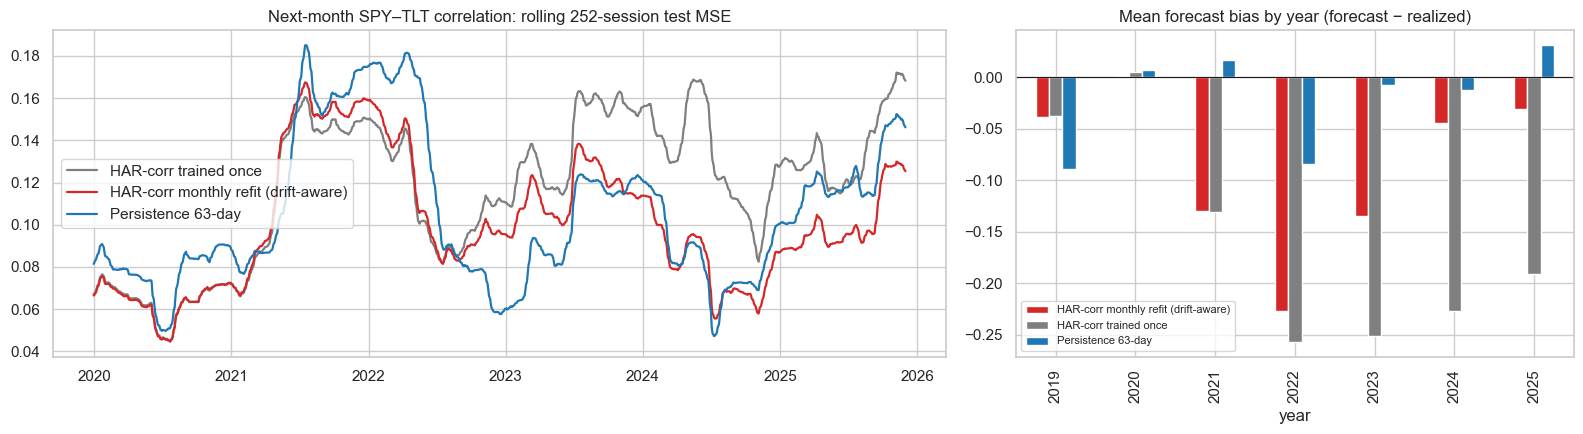

In [6]:
roll = pd.read_csv(R / "v2_test_rolling252.csv", parse_dates=["date"])
pick = {"fixed:lin/hc/fixed": ("HAR-corr trained once", "tab:gray"),
        "spy_tlt_corr.5": ("HAR-corr monthly refit (drift-aware)", "tab:red"),
        "base:persist_63": ("Persistence 63-day", "tab:blue")}
by_year = pd.read_csv(R / "v2_test_by_year.csv")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
for m, (lab, c) in pick.items():
    s = roll[(roll.target == "spy_tlt_corr") & (roll.model == m)].set_index("date")["rolling252_mse"]
    axes[0].plot(s, label=lab, color=c, lw=1.6)
axes[0].set_title("Next-month SPY–TLT correlation: rolling 252-session test MSE"); axes[0].legend()
yb = (by_year[(by_year.target == "spy_tlt_corr") & by_year.model.isin(pick)]
      .assign(model=lambda d: d.model.map(lambda m: pick[m][0])).pivot(index="year", columns="model", values="bias"))
col_of = {lab: c for lab, c in pick.values()}
yb.plot.bar(ax=axes[1], color=[col_of[c] for c in yb.columns])
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_title("Mean forecast bias by year (forecast − realized)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "corr_drift.png", bbox_inches="tight"); plt.show()

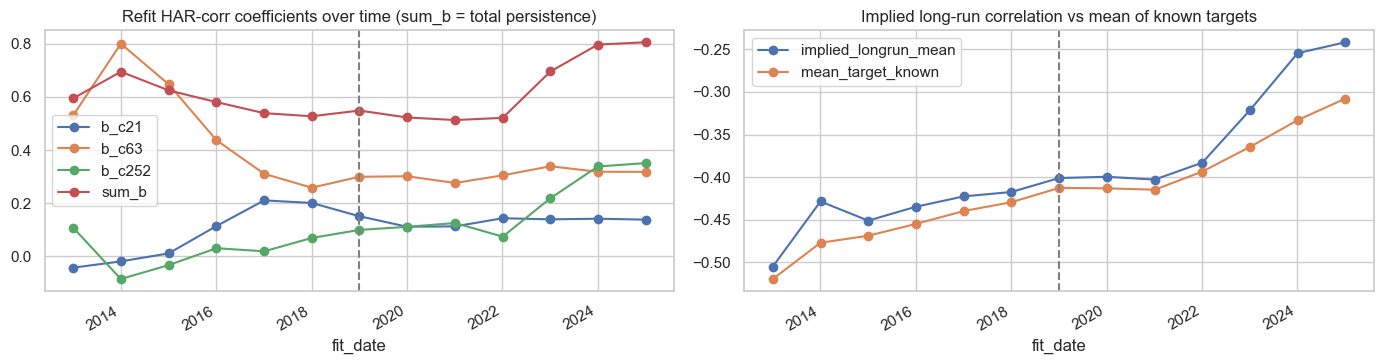

In [7]:
coef = pd.read_csv(R / "v2_expl_corr_coefficients.csv", parse_dates=["fit_date"]).set_index("fit_date")
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
coef[["b_c21", "b_c63", "b_c252", "sum_b"]].plot(ax=axes[0], marker="o")
axes[0].set_title("Refit HAR-corr coefficients over time (sum_b = total persistence)")
coef[["implied_longrun_mean", "mean_target_known"]].plot(ax=axes[1], marker="o")
axes[1].set_title("Implied long-run correlation vs mean of known targets")
for a in axes: a.axvline(pd.Timestamp("2019-01-01"), color="gray", ls="--")
plt.tight_layout(); plt.savefig(FIG / "corr_coefficients.png", bbox_inches="tight"); plt.show()

**Mechanism:** about 94% of the gain is **bias removal**. The trained-once model learned from 2008–2018 that stock–bond correlation reverts to about −0.40, and kept forecasting it after 2022. Refitting raises the model's persistence (the sum of its lag coefficients goes from 0.55 to 0.82) and moves the implied long-run mean toward −0.22, so the forecasts follow the new regime. The model's ability to *rank* months (AUC) barely changes.

In [8]:
for f, title in [("v2audit_robust_startdates.csv", "Alternative test windows (Δ vs trained once and vs persistence-63)"),
                 ("v2audit_robust_loyo.csv", "Leave-one-year-out"),
                 ("v2audit_robust_dm.csv", "Diebold–Mariano with Newey–West standard errors")]:
    print(title); display(pd.read_csv(R / f).round(4))

Alternative test windows (Δ vs trained once and vs persistence-63)


,start,end,n,mse_fixed,mse_r21,mse_p63,rel,d_fixed,lo,hi,p,d_p63,lo_p63,hi_p63
0,2015-01-01,2025-12-31,2745,0.1193,0.1071,0.1207,0.1017,0.0121,0.0018,0.0220,0.0085,0.0136,0.0003,0.0260
1,2017-01-01,2025-12-31,2241,0.1172,0.0992,0.1083,0.1531,0.0179,0.0059,0.0286,0.0005,0.0091,-0.0061,0.0231
2,2019-01-01,2025-12-31,1739,0.1194,0.1018,0.1091,0.1470,0.0176,0.0042,0.0300,0.0025,0.0072,-0.0108,0.0232
3,2020-01-01,2025-12-31,1487,0.1315,0.1078,0.1137,0.1800,0.0237,0.0067,0.0403,0.0025,0.0059,-0.0142,0.0255
4,2021-01-01,2025-12-31,1234,0.1463,0.1151,0.1189,0.2127,0.0311,0.0104,0.0515,0.0010,0.0037,-0.0185,0.0293
5,2022-01-01,2025-12-31,982,0.1388,0.1039,0.1044,0.2514,0.0349,0.0140,0.0556,0.0010,0.0005,-0.0184,0.0155
6,2022-07-01,2025-12-31,858,0.1277,0.1062,0.1084,0.1681,0.0215,0.0034,0.0375,0.0080,0.0022,-0.0159,0.0202
7,2023-01-01,2025-12-31,731,0.1123,0.1067,0.1196,0.0495,0.0056,-0.0056,0.0140,0.1935,0.0129,-0.0019,0.0266
8,2019-01-01,2021-12-31,757,0.0964,0.0991,0.1151,-0.0283,-0.0027,-0.0061,-0.0001,0.9785,0.0159,-0.0202,0.0477
9,2019-01-01,2022-12-31,1008,0.1000,0.0983,0.1014,0.0175,0.0017,-0.0036,0.0061,0.3870,0.0031,-0.0237,0.0314


Leave-one-year-out


,dropped,n,d_fixed,lo,hi,p_boot,p_dm42,year_only_d,year_share_of_total
0,2019,1487,0.0204,0.0045,0.0348,0.0050,0.0031,0.0006,0.0049
1,2020,1486,0.0205,0.0045,0.0350,0.0045,0.0030,0.0002,0.0015
2,2021,1487,0.0220,0.0066,0.0362,0.0025,0.0013,-0.0090,-0.0741
3,2022,1488,0.0179,0.0023,0.0329,0.0150,0.0085,0.0152,0.1254
4,2023,1489,0.0134,-0.0006,0.0263,0.0315,0.0231,0.0422,0.3455
5,2024,1487,0.0136,0.0023,0.0235,0.0085,0.0055,0.0409,0.3377
6,2025,1510,0.0150,0.0007,0.0267,0.0205,0.0123,0.0345,0.2590
7,drop 2022-2025 (=2019-21),757,-0.0027,-0.0061,-0.0001,0.9785,0.9691,NaN,NaN
8,drop 2023-2025,1008,0.0017,-0.0036,0.0061,0.3870,0.2307,NaN,NaN
9,drop 2023+2024,1237,0.0078,-0.0012,0.0140,0.0600,0.0490,NaN,NaN


Diebold–Mariano with Newey–West standard errors


,vs,lag,d,t_dm,p_dm,t_hln,p_hln
0,fixed,20,0.0176,3.0342,0.0012,2.9984,0.0014
1,fixed,42,0.0176,2.7488,0.0030,2.7164,0.0033
2,fixed,63,0.0176,2.6405,0.0041,2.6094,0.0046
3,fixed,126,0.0176,2.5694,0.0051,2.5391,0.0056
4,persist_63,20,0.0072,0.8790,0.1897,0.8687,0.1926
5,persist_63,42,0.0072,0.8157,0.2073,0.8061,0.2102
6,persist_63,63,0.0072,0.8274,0.2040,0.8176,0.2068
7,persist_63,126,0.0072,0.8709,0.1919,0.8606,0.1948


**Caveats from the audit:**
* **The win depends on one regime change.** It appears only once 2–3 years of the new regime are in the test window. A test that ends in 2022 shows no gain, and dropping any two of 2022–2024 makes it non-significant.
* **It is not significant study-wide.** Across all 36 pre-registered tests in this study, the Holm-adjusted *p* is about 0.08.
* **Validation said not to refit.** This configuration came from a default slot in the shortlist. A practitioner following validation would not have deployed it.
* **The target was chosen with hindsight.** It was chosen after the 2022 flip was public knowledge; only the *method comparison* was pre-registered.
* **It does not beat a simple 63-day persistence forecast** (Δ MSE +0.007 [−0.011, +0.023]). Refitting mostly turns the model *into* persistence.
* **Faster-forgetting methods did worse:** rolling 252-session windows, 21-row bias correction, RLS with λ = 0.99 and Page–Hinkley all lost.

### C.2 Volatility: drift handling adds nothing

For SPY and TLT volatility, no drift-aware variant beats HAR-X trained once (all Holm *p* = 1). HAR-X already tracks volatility regimes through its lagged-RV and VIX inputs, and its yearly bias changes sign from year to year, so there is no persistent level shift to correct. The audit's synthetic test confirmed the methods were not sabotaged: when a +0.3 log-volatility shift that the features cannot see is injected, bias correction, recalibration, decay and RLS recover 30–48% of the excess MSE.

## Part D: More feature engineering and feature selection (SPY direction)

**Feature engineering.** 66 new causal features in 7 families were added to the 122 baseline features, using 15 extra Yahoo series. A truncation test confirms they use no future data.

| Family | Examples |
|---|---|
| Volatility surface | VIX/VIX3M term-structure slope, VVIX (vol-of-vol), SKEW (tail risk) |
| Rates | 10y/5y/3m Treasury yields, 10y–3m curve slope and their changes |
| Credit and inflation | HYG/LQD/TIP minus IEF returns, high-yield trend and volatility |
| Global and macro | EEM/EFA minus SPY, US dollar (UUP), oil (USO), commodities (DBC) |
| Breadth | equal-weight (RSP) minus cap-weight SPY |
| Return structure | volatility-scaled returns, variance ratio, autocorrelation, drawdown, Amihud illiquidity, streaks, overnight vs intraday drift, downside-vol ratio, kurtosis |
| Calendar | turn-of-month, option-expiration week |

**Feature selection.** 18 feature sets were compared. Every selector is **re-fitted inside each training window**: once for the *fixed* scheme, and again at every quarterly refit for the *refit* scheme, which makes feature selection itself adaptive. The sets are:
- the 122 baseline features and all 188 features;
- an a-priori core set (23) and core-plus (33);
- L1 stability selection;
- mutual-information top-k;
- correlation-cluster de-duplication;
- **sign-stability filtering**, a drift-aware selector that keeps features whose per-year correlation with the target has a consistent sign;
- GBDT permutation importance;
- PCA;
- greedy forward selection over feature families.

Each set was paired with 3 models and both schemes, for 648 validation runs over 2013–14, 2015–16 and 2017–18. A shortlist of 5 configurations per horizon was hash-locked before a single test run.

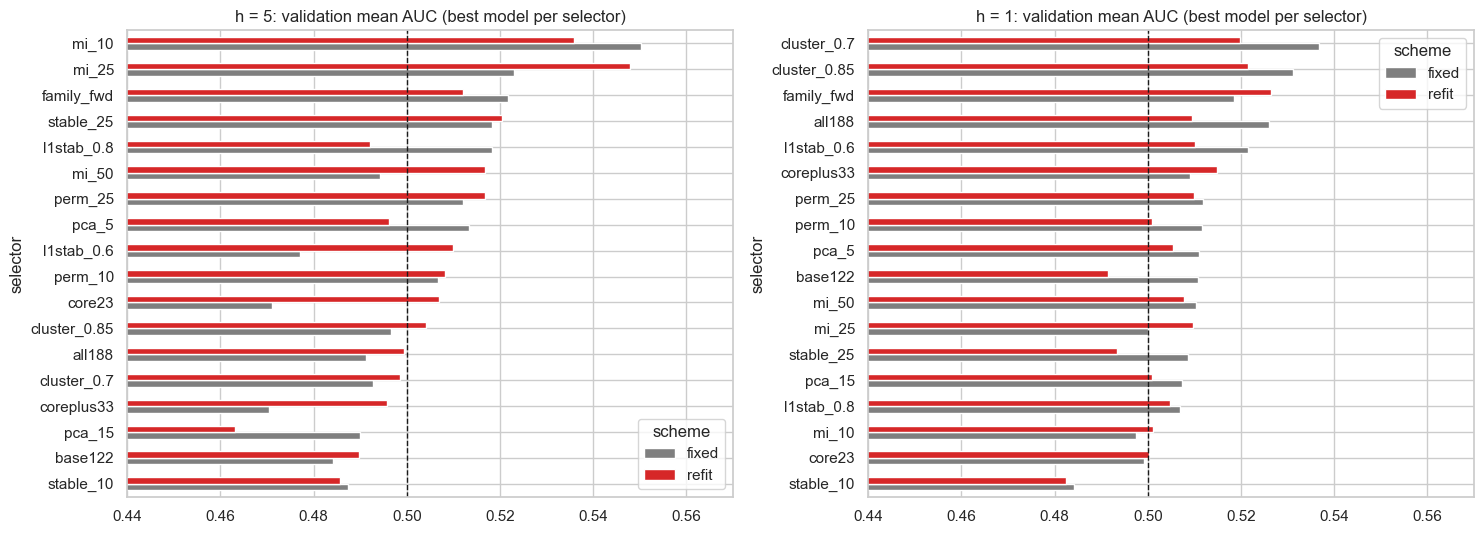

In [9]:
vt = pd.read_csv(R / "fe_validation_table.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, h in zip(axes, [5, 1]):
    p = vt[vt.horizon == h].groupby(["selector", "scheme"])["mean_auc"].max().unstack()
    p = p.loc[p.max(axis=1).sort_values().index]
    p.plot.barh(ax=ax, color=["tab:gray", "tab:red"])
    ax.axvline(0.5, color="k", ls="--", lw=1)
    ax.set_xlim(0.44, 0.57); ax.set_title(f"h = {h}: validation mean AUC (best model per selector)")
plt.tight_layout(); plt.savefig(FIG / "fe_validation.png", bbox_inches="tight"); plt.show()

In [10]:
lvl = pd.read_csv(R / "fe_test_levels.csv")
cmp_ = pd.read_csv(R / "fe_test_comparisons.csv")
short = pd.read_json(R / "fe_shortlist.json")
t = short.merge(lvl, on=["horizon", "selector", "model", "scheme"])
for comp in ["vs_base122", "vs_chance"]:
    c = cmp_[cmp_.comparison == comp].set_index("id")
    t[f"{comp}: dBA [CI]"] = [f"{c.loc[i, 'd_balanced_acc']:+.3f} [{c.loc[i, 'd_balanced_acc_lo']:+.3f}, "
                               f"{c.loc[i, 'd_balanced_acc_hi']:+.3f}]  Holm p={c.loc[i, 'holm_balanced_acc']:.2f}"
                               for i in t.id]
print("Pre-registered shortlist on the 2019-2025 test")
display(t[["id", "selector", "model", "scheme", "val_mean_auc", "balanced_acc", "roc_auc",
           "vs_base122: dBA [CI]", "vs_chance: dBA [CI]"]].set_index("id"))

Pre-registered shortlist on the 2019-2025 test


,selector,model,scheme,val_mean_auc,balanced_acc,roc_auc,vs_base122: dBA [CI],vs_chance: dBA [CI]
id,,,,,,,,
h5.1,mi_10,LR_C0.01,fixed,0.5503,0.5042,0.5080,"-0.014 [-0.051, +0.026] Holm p=1.00","+0.004 [-0.034, +0.045] Holm p=1.00"
h5.2,family_fwd,LR_C0.01,fixed,0.5218,0.5134,0.5081,"-0.004 [-0.041, +0.034] Holm p=1.00","+0.013 [-0.021, +0.052] Holm p=1.00"
h5.3,stable_25,LR_C0.1,refit,0.5205,0.5324,0.5242,"+0.041 [-0.003, +0.084] Holm p=0.30","+0.032 [-0.002, +0.070] Holm p=0.34"
h5.4,perm_25,GBDT,refit,0.5167,0.5044,0.5060,"+0.030 [-0.009, +0.066] Holm p=0.48","+0.004 [-0.035, +0.041] Holm p=1.00"
h5.5,pca_5,GBDT,fixed,0.5133,0.5194,0.5191,"+0.030 [-0.009, +0.070] Holm p=0.48","+0.019 [-0.009, +0.050] Holm p=0.64"
h1.1,cluster_0.7,GBDT,fixed,0.5367,0.4941,0.5039,"-0.010 [-0.040, +0.017] Holm p=1.00","-0.006 [-0.030, +0.018] Holm p=1.00"
h1.2,family_fwd,GBDT,refit,0.5265,0.5100,0.5017,"+0.011 [-0.019, +0.042] Holm p=1.00","+0.010 [-0.013, +0.036] Holm p=1.00"
h1.3,all188,GBDT,fixed,0.5260,0.5080,0.5066,"+0.004 [-0.023, +0.027] Holm p=1.00","+0.008 [-0.016, +0.034] Holm p=1.00"
h1.4,l1stab_0.6,GBDT,fixed,0.5215,0.4939,0.4944,"-0.010 [-0.041, +0.018] Holm p=1.00","-0.006 [-0.029, +0.016] Holm p=1.00"


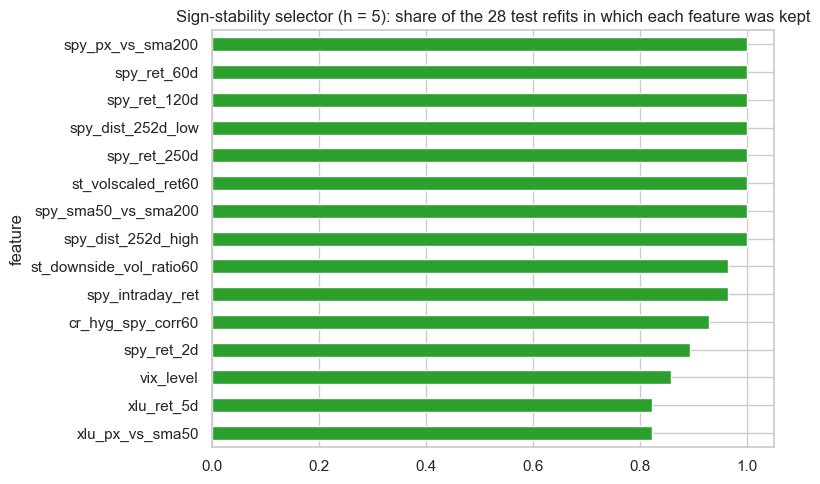

In [11]:
sel = pd.read_csv(R / "fe_selected_features.csv")
top = sel[sel.config == "5/stable_25/LR_C0.1/refit"].sort_values("share_of_fits", ascending=False).head(15)
ax = top.set_index("feature")["share_of_fits"][::-1].plot.barh(figsize=(8, 5), color="tab:green")
ax.set_title("Sign-stability selector (h = 5): share of the 28 test refits in which each feature was kept")
plt.tight_layout(); plt.savefig(FIG / "fe_stable_features.png", bbox_inches="tight"); plt.show()

**Result.** More features and smarter selection did **not** produce a significant improvement.
* **The validation winner did not hold up.** Mutual-information top-10 at h = 5 was above chance in all three validation folds (AUC 0.53, 0.53, 0.59) but fell to 0.51 on test, a textbook case of selection overfitting.
* **Adding all 66 new features hurt the linear models** (188 vs 122 features). Most new families add noise rather than signal for direction.
* **The best test result came from the drift-aware selector.** Sign-stability selection, re-run at every quarterly refit, reached BA 0.532 and AUC 0.524 at h = 5. That is +0.041 BA over the 122-feature model [−0.003, +0.084] and +0.032 over chance [−0.003, +0.070]. Neither interval excludes zero, and after Holm correction *p* = 0.30 and 0.35.
* **It keeps choosing long-horizon trend features:** price vs its 200-day average, 60–250-day returns, and distance from the 52-week high and low. That is classic time-series momentum, a known and economically sensible effect, but here too weak to confirm.
* **At h = 1 nothing came close** (all |Δ| < 0.015).
* **Caveat:** the 2019–2025 test period has now been looked at in several studies of this project, so even a significant result here would deserve extra scepticism.

## Part E: Non-Yahoo data (FRED: macro, credit, financial stress, news-based uncertainty)

Yahoo price data were supplemented with **21 features from 9 FRED series** (Federal Reserve Bank of St. Louis):
- Moody's Baa credit spread
- 10y–2y and 10y–3m yield curves
- 10-year real yield and inflation breakeven
- broad trade-weighted dollar
- St. Louis Fed Financial Stress Index
- initial jobless claims
- the daily **news-based Economic Policy Uncertainty index**, built from newspaper text

**Point-in-time handling.** Each value enters the model only once it would have been *published*:

| Series | Release lag applied |
|---|---|
| Daily market series | +1 session |
| Weekly dollar index | +6 sessions |
| Financial stress index | +7 calendar days |
| Jobless claims | +6 calendar days |
| Policy uncertainty index | +2 sessions |

A truncation test confirms that no later observation changes any feature value. Some series were rejected:
- **Heavy revisions after release:** the Chicago Fed NFCI and the weekly economic index.
- **History too short or ends early:** the ICE high-yield spread (3 years) and the TED spread (ends 2022).
- **Not available in real time:** Fama-French factors (monthly lag).
- **No free history after 2019:** CBOE put/call ratios.

**Pre-registered tests (single run on 2019–2025):**
- **Family A**, no selection at all: 122 baseline features + FRED vs the 122 features alone, for every model × scheme.
- **Family B:** the top 3 FRED-containing sets by validation score vs their twins without FRED.

Adding FRED features vs the same model without them (positive = FRED helps)


,horizon,feature_set,twin,model,scheme,dBA [CI],dAUC [CI],holm_balanced_acc,holm_roc_auc
id,,,,,,,,,
A.h5.0,5,base_fred,base122,LR_C0.01,fixed,"-0.008 [-0.043, +0.020]","-0.010 [-0.048, +0.026]",1.0000,1.0000
A.h5.1,5,base_fred,base122,LR_C0.01,refit,"+0.009 [-0.023, +0.038]","+0.017 [-0.011, +0.044]",1.0000,1.0000
A.h5.2,5,base_fred,base122,LR_C0.1,fixed,"-0.021 [-0.059, +0.011]","-0.012 [-0.053, +0.029]",1.0000,1.0000
A.h5.3,5,base_fred,base122,LR_C0.1,refit,"+0.027 [-0.003, +0.056]","+0.018 [-0.012, +0.047]",0.4440,1.0000
A.h5.4,5,base_fred,base122,GBDT,fixed,"+0.007 [-0.026, +0.039]","+0.019 [-0.012, +0.050]",1.0000,1.0000
A.h5.5,5,base_fred,base122,GBDT,refit,"-0.000 [-0.028, +0.027]","+0.013 [-0.018, +0.043]",1.0000,1.0000
B.h5.12,5,base_fred,base122,LR_C0.1,fixed,"-0.021 [-0.059, +0.011]","-0.012 [-0.053, +0.029]",1.0000,1.0000
B.h5.13,5,spy4_fred,spy4,LR_C0.01,fixed,"-0.022 [-0.086, +0.028]","+0.010 [-0.062, +0.072]",1.0000,1.0000
B.h5.14,5,base_fred,base122,LR_C0.1,refit,"+0.027 [-0.003, +0.056]","+0.018 [-0.012, +0.047]",0.2220,0.5775


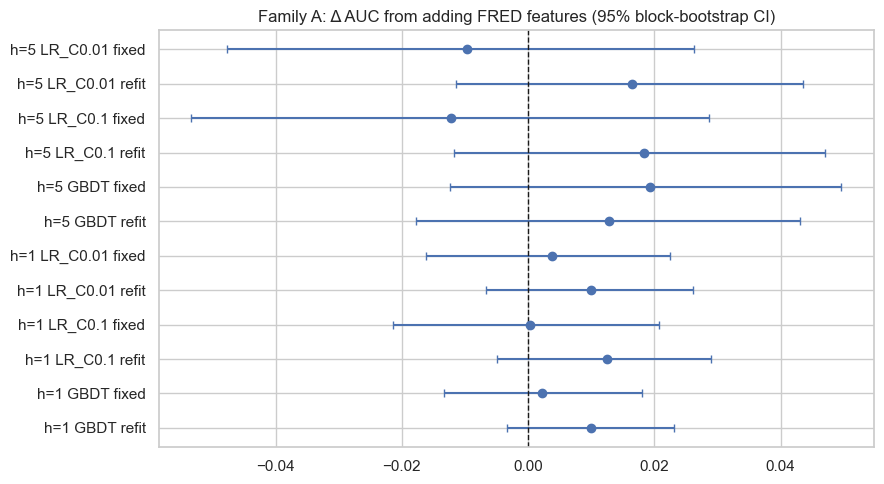

In [12]:
fc = pd.read_csv(R / "fred_test_comparisons.csv")
tw = fc[fc.comparison == "vs_twin"].copy()
tw["dBA [CI]"] = tw.apply(lambda r: f"{r.d_balanced_acc:+.3f} [{r.d_balanced_acc_lo:+.3f}, {r.d_balanced_acc_hi:+.3f}]", axis=1)
tw["dAUC [CI]"] = tw.apply(lambda r: f"{r.d_roc_auc:+.3f} [{r.d_roc_auc_lo:+.3f}, {r.d_roc_auc_hi:+.3f}]", axis=1)
print("Adding FRED features vs the same model without them (positive = FRED helps)")
display(tw[["id", "horizon", "feature_set", "twin", "model", "scheme", "dBA [CI]", "dAUC [CI]",
            "holm_balanced_acc", "holm_roc_auc"]].set_index("id"))

a = tw[tw.family == "A"].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(a))
ax.errorbar(a.d_roc_auc, y, xerr=[a.d_roc_auc - a.d_roc_auc_lo, a.d_roc_auc_hi - a.d_roc_auc], fmt="o", capsize=3)
ax.axvline(0, color="k", ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels([f"h={h} {m} {s}" for h, m, s in zip(a.horizon, a.model, a.scheme)])
ax.set_title("Family A: Δ AUC from adding FRED features (95% block-bootstrap CI)")
plt.tight_layout(); plt.savefig(FIG / "fred_family_a.png", bbox_inches="tight"); plt.show()

**Result:**
- **No significant gain.** No comparison is significant (all Holm *p* ≥ 0.22), and every confidence interval includes zero.
- **A tiny, consistent AUC nudge.** Adding FRED raised AUC in 10 of the 12 no-selection comparisons, by about +0.01. These comparisons share most of their inputs, so the count is not independent evidence. Balanced accuracy does not move consistently.
- **The best single result** was the h = 5 logistic regression with quarterly refits: +0.027 BA [−0.003, +0.056].
- **At h = 1 the effect is essentially zero.**

Macro, credit-stress and news-uncertainty data describe the *risk environment* well, but they do not tell you which way SPY moves next week. This is consistent with these signals already being reflected in prices (and in the VIX, bond and credit ETFs already in the feature set) by the time they are published.

## Conclusions

1. **Drift is real in these markets.** The same SPY-direction model went from AUC 0.37 (2013–14) to about 0.54 (2019–25), logistic coefficients flip sign across refits, and the stock–bond correlation changed regime in 2022.
2. **Accounting for drift does not detectably improve SPY direction prediction.** This held for 206 configurations, 8 method families and two horizons. The cause is weak signal and delayed labels, not broken methods: the same code gains +0.13 to +0.21 AUC on synthetic data with a learnable signal that flips.
3. **The one case where it helps is a large, persistent level shift the features cannot see.** Re-fitting the stock–bond correlation model monthly cut MSE by about 15% versus never re-fitting. That gain is statistically robust within its target, but it is mostly bias removal, needs 2–3 years of the new regime, and is not significant after study-wide correction.
4. **More features and smarter feature selection did not help either.** 66 new features from volatility-surface, rates, credit, global, breadth and return-structure data, combined with 18 feature-selection strategies, gave no significant gain. The most promising variant was a drift-aware "sign-stability" selector that settles on long-horizon momentum features (+0.04 balanced accuracy at h = 5, not significant).
5. **Non-price data didn't help either.** 21 point-in-time features from FRED (credit spreads, yield curve, real yields, dollar, financial stress, jobless claims and news-based policy uncertainty) nudged AUC up by about +0.01 in most comparisons, but no gain is significant.
6. **Simple beats sophisticated.** Plain periodic refitting worked better than fast-forgetting, detector-triggered or ensemble methods, and nothing beat a naive 63-day persistence forecast. For volatility, a HAR model trained once matched every adaptive variant.

**Answer to the research question:** no method works *much* better because it accounts for drift. Adaptation helps only when a target's level shifts persistently and the model's inputs cannot carry that shift. Even then, a simple persistence rule captures the same benefit.

### Reproducing the results
From the project folder, run in order (about 40 minutes in total):
1. Direction study:
   `python experiments/run_validation.py`, `select_shortlist.py`, `run_test.py`, `exploratory_diagnostics.py`
2. Direction audit:
   `audit_tests.py`, `audit_synth.py`, `audit_fixed_methods.py`, `audit_robustness.py`, `audit_core_lr.py`
3. Volatility/correlation study:
   `v2_validation.py`, `v2_select.py`, `v2_checks.py`, `v2_test.py`, `v2_exploratory.py`
4. Volatility/correlation audit:
   `v2audit_leakage.py`, `v2audit_robust.py`, `v2audit_beatp63.py`, `v2audit_vol.py`
5. Feature study:
   `fe_features.py` (also runs the leakage test), `fe_validation.py`, `fe_select.py`, `fe_test.py`
6. FRED study:
   `fred_features.py` (leakage test), then `fred_study.py validate`, `fred_study.py select`, `fred_study.py test`.
   Raw CSVs are in `data/fred/` (from fred.stlouisfed.org).

Full write-ups: `experiments/OPTIMIST_REPORT.md`, `PESSIMIST_AUDIT.md`, `V2_OPTIMIST_REPORT.md`, `V2_PESSIMIST_AUDIT.md`.